# Lab 2 - 17.7.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model in order to predict the “revenue” based on the feature
       “temperature”, using linear regression for the given dataset “icecream.csv”
       with the split of 80 and 20 for training and testing the dataset. Analyze
       the performance and use scatter plot to project the observed and the
       predicted results.

    2. Generate the model in order to predict the “weight” based on the features
       “l1, l2, l3, height, width” using linear regression for the given dataset
       “fishdata.csv” with the following splits for training and testing the
       dataset. Analyze the performance for the below splits and use scatter plot
       to project the observed and the predicted results.

       a) 80:20
       b) 75:25

### 1.

### Icecream - Revenue prediction

#### Load dataset

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [16]:
ice_df = pd.read_csv('Lab 2-17.7.2026/icecream.csv')
ice_df.head()

,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


In [17]:
ice_df.describe()

,Temperature,Revenue
count,500.000000,500.000000
mean,22.281600,522.058000
std,8.097597,175.410399
min,0.000000,10.000000
25%,17.175000,406.000000
50%,22.400000,530.000000
75%,27.800000,643.000000
max,45.000000,1000.000000


#### Train-test split

In [18]:
X = ice_df[['Temperature']]
y = ice_df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1265)

#### Train model

In [19]:
ice_model = LinearRegression()
ice_model.fit(X_train, y_train)

print(f"Coefficient: {ice_model.coef_[0]:.2f}")
print(f"Intercept: {ice_model.intercept_:.2f}")

Coefficient: 21.49
Intercept: 43.40


#### Predictions & performance

In [20]:
y_pred = ice_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.2f}")

MAE: 20.41
MSE: 673.27
RMSE: 25.95
R2 Score: 0.98


#### Scatter plot - observed vs predicted

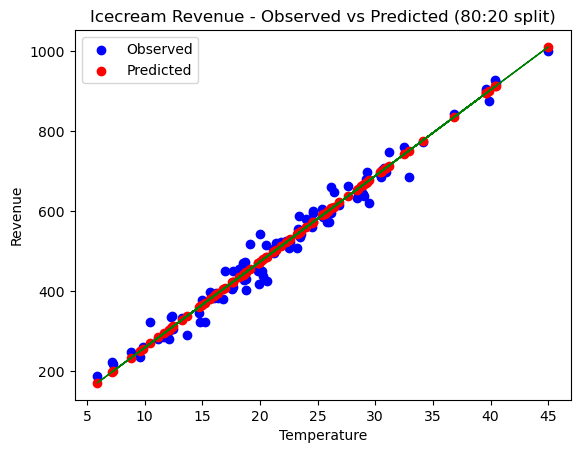

In [21]:
plt.scatter(X_test, y_test, color='blue', label='Observed')
plt.scatter(X_test, y_pred, color='red', label='Predicted')
plt.plot(X_test, y_pred, color='green', linewidth=1)
plt.xlabel('Temperature')
plt.ylabel('Revenue')
plt.title('Icecream Revenue - Observed vs Predicted (80:20 split)')
plt.legend()
plt.show()

### 2.

### Fish - Weight prediction

#### Load dataset

In [22]:
fish_cols = ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']
fish_df = pd.read_csv('Lab 2-17.7.2026/fishdata.csv', names=fish_cols)
fish_df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [23]:
fish_df.describe()

,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


#### Features & target

In [24]:
X_fish = fish_df[['Length1', 'Length2', 'Length3', 'Height', 'Width']]
y_fish = fish_df['Weight']

#### a) 80:20 split

In [25]:
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_fish, y_fish, test_size=0.2, random_state=1265)

fish_model_a = LinearRegression()
fish_model_a.fit(X_train_a, y_train_a)

y_pred_a = fish_model_a.predict(X_test_a)

mae_a = mean_absolute_error(y_test_a, y_pred_a)
mse_a = mean_squared_error(y_test_a, y_pred_a)
rmse_a = np.sqrt(mse_a)
r2_a = r2_score(y_test_a, y_pred_a)

print(f"MAE: {mae_a:.2f}")
print(f"MSE: {mse_a:.2f}")
print(f"RMSE: {rmse_a:.2f}")
print(f"R2 Score: {r2_a:.2f}")

MAE: 105.21
MSE: 15294.35
RMSE: 123.67
R2 Score: 0.89


##### Scatter plot - observed vs predicted (80:20)

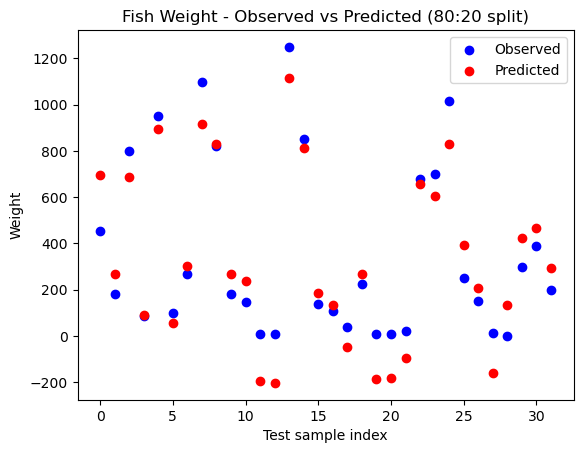

In [26]:
plt.scatter(range(len(y_test_a)), y_test_a, color='blue', label='Observed')
plt.scatter(range(len(y_test_a)), y_pred_a, color='red', label='Predicted')
plt.xlabel('Test sample index')
plt.ylabel('Weight')
plt.title('Fish Weight - Observed vs Predicted (80:20 split)')
plt.legend()
plt.show()

#### b) 75:25 split

In [27]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_fish, y_fish, test_size=0.25, random_state=1265)

fish_model_b = LinearRegression()
fish_model_b.fit(X_train_b, y_train_b)

y_pred_b = fish_model_b.predict(X_test_b)

mae_b = mean_absolute_error(y_test_b, y_pred_b)
mse_b = mean_squared_error(y_test_b, y_pred_b)
rmse_b = np.sqrt(mse_b)
r2_b = r2_score(y_test_b, y_pred_b)

print(f"MAE: {mae_b:.2f}")
print(f"MSE: {mse_b:.2f}")
print(f"RMSE: {rmse_b:.2f}")
print(f"R2 Score: {r2_b:.2f}")

MAE: 106.09
MSE: 16414.50
RMSE: 128.12
R2 Score: 0.87


##### Scatter plot - observed vs predicted (75:25)

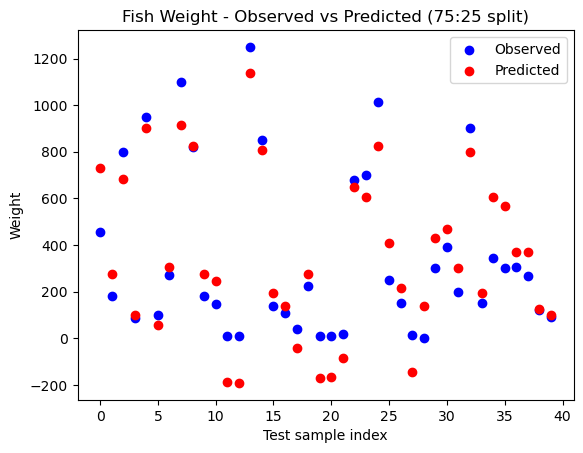

In [28]:
plt.scatter(range(len(y_test_b)), y_test_b, color='blue', label='Observed')
plt.scatter(range(len(y_test_b)), y_pred_b, color='red', label='Predicted')
plt.xlabel('Test sample index')
plt.ylabel('Weight')
plt.title('Fish Weight - Observed vs Predicted (75:25 split)')
plt.legend()
plt.show()